# Polynomial Regression: Fuel Economy versus Horsepower

**Family:** Supervised learning | **Level:** Beginner | **Dataset:** `auto_mpg` | **Runs on:** CPU, about 1 minute(s)

Use one feature to see underfitting and overfitting as the polynomial degree grows.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How polynomial features turn a linear model into a curve
- How the degree trades bias against variance
- How to pick the degree on validation data and not on the test set

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Engine power and fuel use are linked by physics, but the link is curved, not straight.

**The problem.** Predict mpg from horsepower alone and decide how flexible the curve should be.

**Why it matters.** Choosing the wrong flexibility gives either a model that misses real structure or one that memorises noise.

**Why machine learning.** The shape of the curve is learned from cars on the road.

**Why this algorithm.** Polynomial regression is the cleanest way to see the bias variance trade-off: one input, one knob (degree).

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

**Relationship to this notebook.** Hastie et al. discuss basis expansions and the bias variance trade-off, which this notebook shows on real data. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Model.** Expand one input $x$ into powers and fit a linear model on them:

$$\hat y = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

**Objective.** Ordinary least squares on the expanded features, $\min_\beta \lVert y - \Phi\beta \rVert_2^2$, where $\Phi_{ij} = x_i^{\,j}$.

**Bias and variance.** For expected squared error at a point, $\mathbb{E}[(y-\hat f)^2] = \text{bias}^2 + \text{variance} + \sigma^2$. Low degree: high bias. High degree: high variance.

**Assumptions.** The true curve is well approximated by a low degree polynomial inside the data range.

**Limitations.** High degree terms explode outside the data range, and the columns $x^j$ are strongly correlated (we standardise after expansion to help the solver).

## 5. Dataset Introduction

**Auto MPG** (Quinlan, 1993), UCI Machine Learning Repository, licence CC BY 4.0, DOI 10.24432/C5859H. 392 cars from 1970 to 1982 without missing horsepower (as shipped in `mlxtend`). Target `mpg`. Features: `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`, `origin` (1 US, 2 Europe, 3 Japan). All numeric. Limit: old cars only, so conclusions do not transfer to modern vehicles. Here we keep only `horsepower` and `mpg`.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "polynomial_regression"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("auto_mpg")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: regression | target: mpg | shape: (392, 8)


,source
title,Auto MPG
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/9/auto+mpg
license,CC BY 4.0
doi,10.24432/C5859H
rows,392
features,7
limits,Cars from 1970 to 1982 only. Six rows without ...


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,8.0,307.0,130.0,3504.0,12.0,70.0,1.0,18.0
1,8.0,350.0,165.0,3693.0,11.5,70.0,1.0,15.0
2,8.0,318.0,150.0,3436.0,11.0,70.0,1.0,18.0
3,8.0,304.0,150.0,3433.0,12.0,70.0,1.0,16.0
4,8.0,302.0,140.0,3449.0,10.5,70.0,1.0,17.0


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (392, 8)


,columns by dtype
float64,8


,count,mean,std,min,25%,50%,75%,max
cylinders,392.0,5.472,1.706,3.0,4.000,4.00,8.000,8.0
displacement,392.0,194.412,104.644,68.0,105.000,151.00,275.750,455.0
horsepower,392.0,104.469,38.491,46.0,75.000,93.50,126.000,230.0
weight,392.0,2977.584,849.403,1613.0,2225.250,2803.50,3614.750,5140.0
acceleration,392.0,15.541,2.759,8.0,13.775,15.50,17.025,24.8
model_year,392.0,75.980,3.684,70.0,73.000,76.00,79.000,82.0
origin,392.0,1.577,0.806,1.0,1.000,1.00,2.000,3.0
mpg,392.0,23.446,7.805,9.0,17.000,22.75,29.000,46.6


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


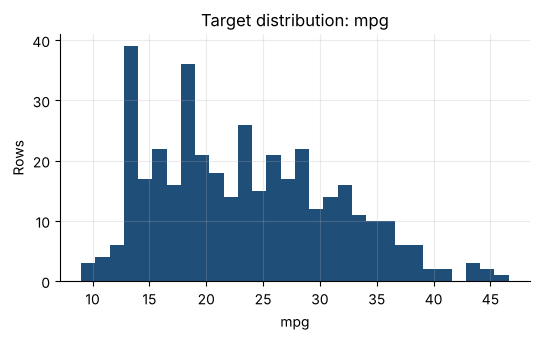

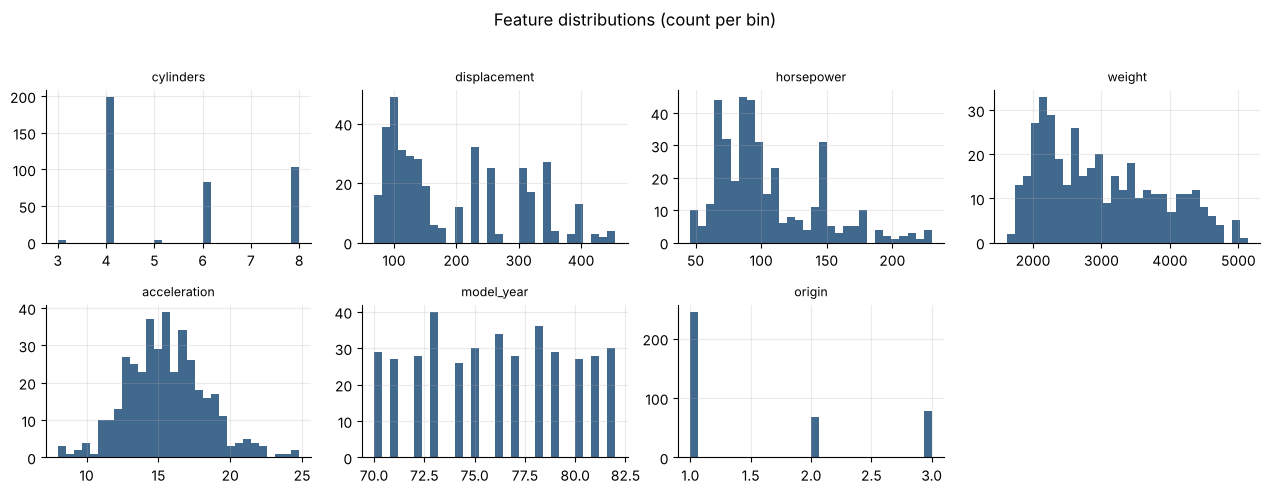

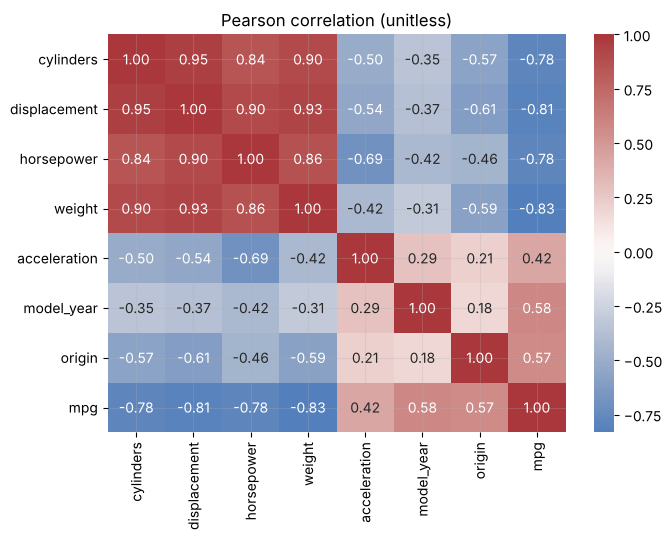

,feature,outliers,percent
0,acceleration,11,2.81
1,horsepower,10,2.55
2,cylinders,0,0.00
3,displacement,0,0.00
4,weight,0,0.00
5,model_year,0,0.00
6,origin,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:
data = data[['horsepower', 'mpg']].copy()   # one feature on purpose
X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 234 79 79
transformed train shape: (234, 1)


## 8. Algorithm Implementation

### 8.1 Concept

A degree $d$ polynomial has $d+1$ parameters. Too few parameters cannot follow the curve (underfit), too many follow the noise (overfit).

### 8.2 Python implementation from scratch

Not implemented from scratch: it is the linear regression notebook applied to expanded columns. The sweep below is the educational part.

### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `degree` | Highest power of the input. The main complexity knob. |
| `include_bias` | Whether to add a constant column. Off here because the model has its own intercept. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [6]:
SELECT = "RMSE"
LOWER_IS_BETTER = True
SCORING = "neg_root_mean_squared_error"
SWEEP_PARAM = "model__polynomialfeatures__degree"
SWEEP_VALUES = [1, 2, 3, 4, 5, 6, 8, 10]

def build_pipeline():
    return make_model_pipeline(X_train, make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression()), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])


,RMSE,R2,MAE
model__polynomialfeatures__degree,,,
1,5.0525,0.4722,3.8710
2,4.4634,0.5881,3.1880
3,4.5005,0.5812,3.2202
4,4.4994,0.5814,3.2210
5,4.3701,0.6052,3.1401
6,4.3317,0.6120,3.1020
8,4.5154,0.5784,3.2372
10,4.9832,0.4866,3.3363


best model__polynomialfeatures__degree on validation: 6
refit on train plus validation rows


## 10. Evaluation

Regression metrics: MAE (average absolute error in target units), RMSE (square root of the mean squared error, same unit, punishes large errors), R-squared (share of variance explained, can be negative on new data) and MAPE when the target is never zero.

A dummy model gives the floor every real model must beat.

In [7]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "PolynomialRegression": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="PolynomialRegression", dataset="auto_mpg",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,MAE,MSE,RMSE,R2,MAPE_percent
baseline,5.8810,51.6203,7.1847,-0.0114,30.1965
PolynomialRegression,3.2517,17.5269,4.1865,0.6566,14.6609


5-fold CV neg_root_mean_squared_error: mean -4.4097, std 0.1514
saved polynomial_regression.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

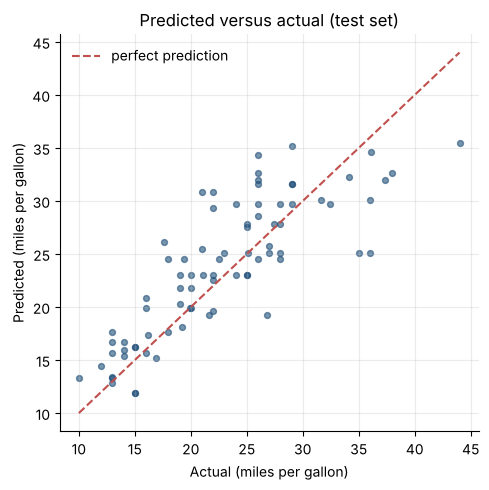

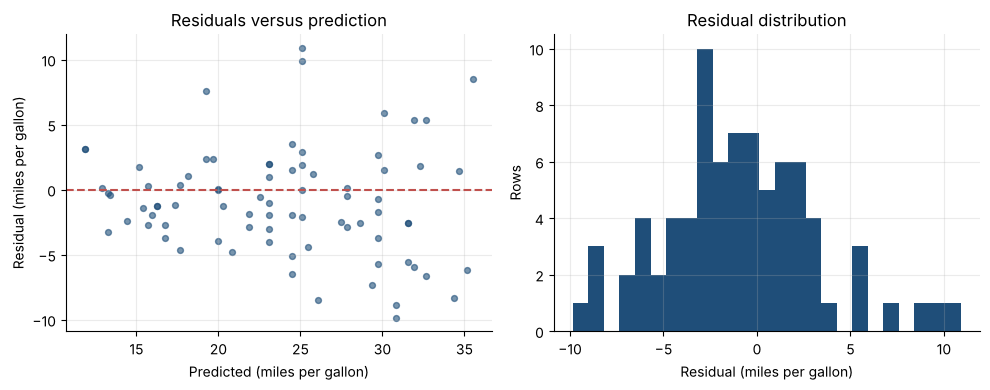

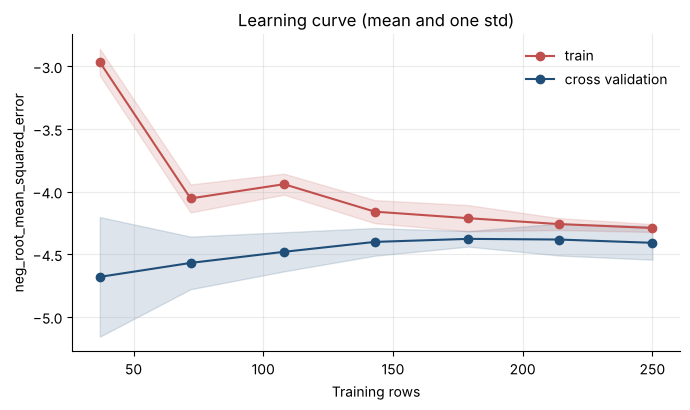

In [8]:
pred = final_model.predict(X_test)
fig = viz.plot_pred_vs_actual(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "pred_vs_actual"); plt.show()
fig = viz.plot_residuals(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "residuals"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()

## 12. Interpretation

Permutation importance shuffles one feature and measures how much the error grows. Correlated features share importance, so read it as a ranking of groups. Check the residual plot for curvature or funnel shapes, which mean the model misses structure or the error variance changes with the prediction.

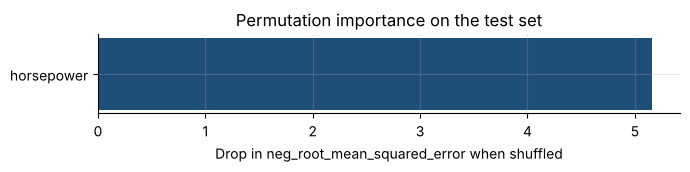

Top features: horsepower
Largest test errors:


,actual,predicted,abs_error
374,36.0,25.108,10.892
332,35.0,25.108,9.892
108,21.0,30.841,9.841
45,22.0,30.841,8.841
388,44.0,35.501,8.499



Test RMSE: 4.1865 | baseline RMSE: 7.1847
Cross validation spread (std): 0.1514. A test gap larger than this spread is meaningful.


In [9]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Training versus validation error by degree

Plot both errors against the degree. The gap between them grows when the model overfits.

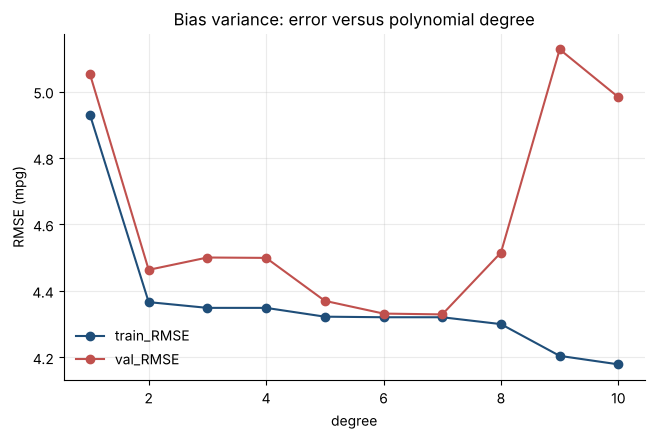

,train_RMSE,val_RMSE
degree,,
1,4.930,5.052
2,4.366,4.463
3,4.349,4.501
4,4.349,4.499
5,4.322,4.370
6,4.321,4.332
7,4.321,4.329
8,4.300,4.515
9,4.204,5.127


In [10]:
rows = []
for degree in range(1, 11):
    m = clone(pipe).set_params(model__polynomialfeatures__degree=degree).fit(X_train, y_train)
    rows.append({"degree": degree, "train_RMSE": evaluate_estimator(m, X_train, y_train, TASK)["RMSE"],
                 "val_RMSE": evaluate_estimator(m, X_val, y_val, TASK)["RMSE"]})
curve = pd.DataFrame(rows).set_index("degree")
curve.plot(marker="o")
plt.ylabel("RMSE (mpg)"); plt.title("Bias variance: error versus polynomial degree"); plt.show()
display(curve.round(3))

### Experiment 2: Fitted curves

Draw the fitted curve for three degrees over the data.

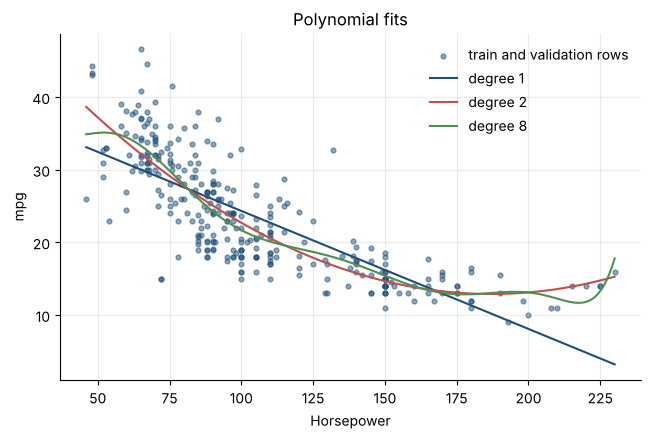

In [11]:
grid = pd.DataFrame({"horsepower": np.linspace(X_trainval["horsepower"].min(), X_trainval["horsepower"].max(), 200)})
plt.scatter(X_trainval["horsepower"], y_trainval, s=12, alpha=0.5, label="train and validation rows")
for degree in [1, 2, 8]:
    m = clone(pipe).set_params(model__polynomialfeatures__degree=degree).fit(X_trainval, y_trainval)
    plt.plot(grid["horsepower"], m.predict(grid), label=f"degree {degree}")
plt.xlabel("Horsepower"); plt.ylabel("mpg"); plt.legend(); plt.title("Polynomial fits"); plt.show()

### Experiment 3: Add regularisation to a high degree

Degree 8 overfits. Ridge shrinkage can tame it. Compare cross validated RMSE.

In [12]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
from sklearn.linear_model import Ridge
raw = cv_rmse(make_pipeline(PolynomialFeatures(8, include_bias=False), StandardScaler(), LinearRegression()))
shrunk = cv_rmse(make_pipeline(PolynomialFeatures(8, include_bias=False), StandardScaler(), Ridge(alpha=10)))
print(f"degree 8 plain: {raw[0]:.3f} +- {raw[1]:.3f}")
print(f"degree 8 ridge: {shrunk[0]:.3f} +- {shrunk[1]:.3f}")

degree 8 plain: 4.404 +- 0.137
degree 8 ridge: 4.588 +- 0.306


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Add one more feature or remove one and explain the change using cross validation.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

The polynomial view of regression is textbook material in Hastie et al. Our sweep reproduces the qualitative U shape of validation error that they describe, on a different dataset.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use splines or a generalised additive model for smoother local flexibility, and cross validation with more folds for the degree choice.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Degree is a complexity knob.
- Choose it on validation data.
- Extrapolation with high degree polynomials is dangerous.

**Use cases.** Calibration curves, simple trend fits, teaching bias and variance.

**Limitations.** Global basis, poor extrapolation, correlated columns.

**Recommended next notebook.** Ridge Regression.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.